# 압축 흔적 직접 측정 EDA

- 작성자: kimjihwan
- 상태: **작성 중**
- 작성일: 2026-11-24
- 관련 작업: T06 저장 품질 차이 논의, T14 JPEG 증강
- [보고서](../../docs/eda/EXP_kimjihwan_006_compression_trace_check.md) · 관련: [seonghun 003 JPEG 저장 이력](../../docs/eda/EXP_seonghun_003_jpeg_history_check.md) · [004 RGB+ELA U-Net](../../docs/rgb_ela_unet/EXP_kimjihwan_004_rgb_ela_unet_baseline.md)

## 목적

seonghun 003은 파일 단위로 정상 원본이 모두 Q75, JPEG100 조작본이 모두 Q100임을 확인했지만, **이미지 안의 이중 압축 여부는 확인하지 않았음**. 002~004 U-Net은 AutoSplice JPEG100에서 높고 JPEG90·75와 CocoGlide에서 무너졌는데, 그 이유로 다음 가설을 세웠음.

- **가설 A:** JPEG100 조작본의 마스크 밖은 Q75 원본을 Q100으로 다시 저장한 영역이라 Q75 양자화 흔적이 남아 있고, 마스크 안은 새로 생성돼 Q100으로 한 번만 저장돼 그 흔적이 없음. 모델이 이 차이로 위치를 찾았을 수 있음.
- **가설 B:** JPEG90·75 조작본은 이미지 전체가 다시 압축돼 그 차이가 약해지거나 사라짐.
- **가설 C:** CocoGlide는 COCO JPEG를 크기 조정해 PNG로 저장한 이미지라 8×8 JPEG 격자 흔적이 남아 있지 않음.

모델을 쓰지 않고 손으로 만든 압축 지표만으로 이 가설을 직접 측정함. GPU가 필요 없음(CPU 런타임). 측정에는 test split과 CocoGlide를 쓰지만 모델 선택이나 설정 변경에는 쓰지 않음.

## 측정 지표

- **Q75 격자 정렬도:** 휘도(Y)를 8×8 블록 DCT로 바꿔 저주파 AC 계수(u+v=1~4, 14개)를 표준 Q75 휘도 양자화 표로 나눈 값이 정수에서 얼마나 떨어졌는지의 평균(0~0.5). Q75로 저장된 적이 있는 블록은 0에 가깝고, 흔적이 없으면 약 0.25임. 값이 양자화 간격의 절반보다 작은 계수(0으로 양자화됐을 계수)는 제외함.
- **블록 판별력(AUC):** 이미지마다 정렬도를 "마스크 안 블록일수록 크다"는 점수로 보고 안·밖 블록을 가르는 AUC를 구함. 0.5는 구분 불가, 1에 가까울수록 손으로 만든 지표만으로 위치를 찾을 수 있다는 뜻임. ELA 블록 평균으로도 같은 AUC를 구함.
- **ELA 안·밖 평균:** 모델 입력과 같은 ELA(quality 90, scale 15, subsampling 2)의 마스크 안·밖 평균.
- **블록 경계 강도(BAI):** 8의 배수 경계에서의 인접 픽셀 차이를 그 밖의 인접 차이로 나눈 값. JPEG 격자가 남아 있으면 1보다 큼.
- **CocoGlide 전부 조작 예측 기준선:** 모든 픽셀을 조작으로 예측했을 때의 이미지별 F1 평균.

## 1. Drive·공통 코드·실행 환경 준비

공유 Drive의 데이터와 공통 코드를 읽음. 이미지별 측정 결과는 개인 폴더 `MyDrive/AI_Forensics_runs/kimjihwan/`에 CSV로 저장함.

In [1]:
from pathlib import Path
from google.colab import drive
from io import BytesIO
import hashlib
import importlib
import importlib.metadata
import json
import os
import platform
import sys
import time
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.fft import dctn
from scipy.stats import mannwhitneyu
from PIL import Image, features
from IPython.display import display

drive.mount("/content/drive")
shared_root = Path("/content/drive/MyDrive/AI_Forensics")
project_root = shared_root / "project"
work_root = Path("/content")
data_root = work_root / "datasets"
experiment_name = "EXP_kimjihwan_006_compression_trace_check"
run_root = Path("/content/drive/MyDrive/AI_Forensics_runs/kimjihwan") / experiment_name
split_path = project_root / "scripts/splits/autosplice_seed42.csv"
archive_paths = {
    "AutoSplice": shared_root / "datasets/AutoSplice/AutoSplice.zip",
    "CocoGlide": shared_root / "datasets/CocoGlide.zip",
}
extract_paths = {"AutoSplice": data_root, "CocoGlide": data_root / "CocoGlide"}
required = ["scripts/__init__.py", "scripts/datasets.py", "scripts/preprocessing.py", "scripts/evaluation.py",
            "scripts/splits/autosplice_seed42.csv"]
for relative in required:
    if not (project_root / relative).is_file():
        raise FileNotFoundError(f"Drive에 공통 파일을 업로드해야 함: {relative}")

sys.path.insert(0, str(project_root))
importlib.invalidate_caches()
import scripts
import scripts.datasets as dataset_module
import scripts.preprocessing as preprocessing_module
import scripts.evaluation as evaluation_module

for module, relative in [(scripts, "scripts/__init__.py"), (dataset_module, "scripts/datasets.py"),
                         (preprocessing_module, "scripts/preprocessing.py"), (evaluation_module, "scripts/evaluation.py")]:
    if Path(module.__file__).resolve() != (project_root / relative).resolve():
        raise ImportError(f"프로젝트의 모듈을 불러오도록 커널을 재시작해야 함: {relative}")
    print("불러온 코드:", module.__file__)

from scripts.datasets import sha256, prepare_dataset_zip, autosplice_records, cocoglide_records
from scripts.preprocessing import load_rgb, load_binary_mask, make_ela
from scripts.evaluation import pixel_f1

print("실행 시각 UTC:", datetime.now(timezone.utc).isoformat())
print("Python:", platform.python_version())
print("OS:", platform.platform())
for package in ("numpy", "scipy", "Pillow", "pandas", "matplotlib"):
    print(package, importlib.metadata.version(package))
print("JPEG library:", features.version("jpg"))
print("CPU 코어:", os.cpu_count())
print("실행 기록 폴더:", run_root)

Mounted at /content/drive
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/__init__.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/datasets.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/preprocessing.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/evaluation.py
실행 시각 UTC: 2026-11-24T16:00:53.452052+00:00
Python: 3.13.18
OS: Linux-6.6.159+-x86_64-with-glibc2.39
numpy 2.4.6
scipy 1.16.3
Pillow 11.3.0
pandas 2.2.3
matplotlib 3.10.0
JPEG library: 6.2
CPU 코어: 8
실행 기록 폴더: /content/drive/MyDrive/AI_Forensics_runs/kimjihwan/EXP_kimjihwan_006_compression_trace_check


In [2]:
# Git 저장소의 LF 줄바꿈 기준 해시임. Windows에서 CRLF로 바뀐 파일을 올리면 일치하지 않음.
expected_files = {
    "scripts/__init__.py": "e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855",
    "scripts/datasets.py": "435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88",
    "scripts/preprocessing.py": "73ce7fa0aee3f2b901a9ab04d430ff8ae2bcaa7262005600f6b08f04b95c652f",
    "scripts/evaluation.py": "ad400aa2cf453bd54ecc3e73abc38bc80cb1f7239eea7489b3072dae96dfcb52",
    "scripts/splits/autosplice_seed42.csv": "f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e",
}
for relative, expected_hash in expected_files.items():
    actual_hash = sha256(project_root / relative)
    print(relative, actual_hash)
    if actual_hash != expected_hash:
        raise ValueError(f"검토한 코드·분할 버전과 일치해야 함: {relative}")

config = dict(
    split="test", autosplice_qualities=[100, 90, 75], mask_foreground=255,
    ela_quality=90, ela_scale=15, ela_subsampling=2,
    dct="8x8 orthonormal DCT-II of decoded luma (JPEG: decoder YCbCr via draft) minus 128",
    alignment_coefficients="AC with u+v in 1..4 (14 coefficients)", alignment_min_coefficients=3,
    alignment_skip="|coef| < q/2", reference_tables=[75, 90], min_blocks_for_auc=5,
    cocoglide_jpeg_quality=100, cocoglide_jpeg_subsampling=0, seed=42,
)
for key, value in config.items():
    print(f"{key}: {value}")

scripts/__init__.py e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855
scripts/datasets.py 435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88
scripts/preprocessing.py 73ce7fa0aee3f2b901a9ab04d430ff8ae2bcaa7262005600f6b08f04b95c652f
scripts/evaluation.py ad400aa2cf453bd54ecc3e73abc38bc80cb1f7239eea7489b3072dae96dfcb52
scripts/splits/autosplice_seed42.csv f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e
split: test
autosplice_qualities: [100, 90, 75]
mask_foreground: 255
ela_quality: 90
ela_scale: 15
ela_subsampling: 2
dct: 8x8 orthonormal DCT-II of decoded luma (JPEG: decoder YCbCr via draft) minus 128
alignment_coefficients: AC with u+v in 1..4 (14 coefficients)
alignment_min_coefficients: 3
alignment_skip: |coef| < q/2
reference_tables: [75, 90]
min_blocks_for_auc: 5
cocoglide_jpeg_quality: 100
cocoglide_jpeg_subsampling: 0
seed: 42


## 2. 데이터 준비

AutoSplice test 조작 이미지를 JPEG 100·90·75에서 각각, 정상 원본(Q75)을 한 번 측정함. CocoGlide는 PNG 원본에서 BAI를 재고, ELA는 U-Net 평가 입력과 같은 JPEG100 4:4:4 변환본에서 잼.

In [3]:
archive_hashes = {
    "AutoSplice": "0d94e2df6842f44c11e21ee207707c49fd9717ec89048bd6f28fc1e07c4a5e36",
    "CocoGlide": "fc848643ad0a81010ba2a6ab8c055762782f54e4fb9e407210dbfe1c3b538af9",
}
for name, source in archive_paths.items():
    prepare_dataset_zip(source, work_root / f"{name}.zip", extract_paths[name], archive_hashes[name])

autosplice = []
for quality in config["autosplice_qualities"]:
    for record in autosplice_records(data_root / "AutoSplice", split_path, quality=quality):
        if record["split"] != config["split"] or (record["kind"] == "normal" and quality != 100):
            continue
        autosplice.append(dict(record, variant="original" if record["kind"] == "normal" else f"JPEG{quality}"))

cocoglide_root = data_root / "CocoGlide"
jpeg_root = work_root / "unet_inputs" / "CocoGlide_JPEG100_444"
cocoglide = []
for record in cocoglide_records(cocoglide_root):
    source = record["image_path"]
    target = (jpeg_root / source.relative_to(cocoglide_root)).with_suffix(".jpg")
    target.parent.mkdir(parents=True, exist_ok=True)
    with Image.open(source) as image:
        if image.format != "PNG":
            raise ValueError(f"CocoGlide 원본은 PNG여야 함: {source}")
        image.convert("RGB").save(target, format="JPEG", quality=config["cocoglide_jpeg_quality"],
                                  subsampling=config["cocoglide_jpeg_subsampling"])
    cocoglide.append(dict(record, jpeg_path=target))

display(pd.DataFrame(autosplice).groupby(["variant", "kind"]).size().rename("images").reset_index())
display(pd.DataFrame(cocoglide).groupby("kind").size().rename("images").reset_index())

AutoSplice ZIP SHA-256 확인 및 압축 해제 완료
CocoGlide ZIP SHA-256 확인 및 압축 해제 완료


,variant,kind,images
0,JPEG100,manipulated,335
1,JPEG75,manipulated,335
2,JPEG90,manipulated,335
3,original,normal,228


,kind,images
0,manipulated,512
1,normal,512


## 3. 측정 함수와 대조 확인

JPEG 파일은 디코더의 YCbCr 출력(`draft`)에서 휘도를 직접 읽어 RGB 변환의 반올림 오차를 피함. 표준 양자화 표는 Pillow로 저장한 파일에서 읽음.

지표가 의도대로 동작하는지 정상 원본 한 장으로 먼저 확인함. Q75 파일 그대로, Q100으로 다시 저장(격자 유지)한 것은 정렬도가 낮아야 하고, 4픽셀 밀어 저장하거나 0.9배로 줄여 저장해 격자를 깬 것은 약 0.25여야 함.

In [4]:
def standard_luma_table(quality):
    with BytesIO() as buffer:
        Image.new("RGB", (16, 16)).save(buffer, format="JPEG", quality=quality)
        buffer.seek(0)
        with Image.open(buffer) as image:
            return np.array(image.quantization[0], dtype=np.float64).reshape(8, 8)


tables = {q: standard_luma_table(q) for q in config["reference_tables"]}
assert tables[75][0, 0] == 8 and tables[75][0, 1] == 6, "Pillow의 Q75 표준 휘도 표여야 함"
u, v = np.meshgrid(np.arange(8), np.arange(8), indexing="ij")
coefficient_mask = ((u + v) >= 1) & ((u + v) <= 4)
print("Q75 휘도 표(8×8):")
print(tables[75].astype(int))


def luma_from_image(image):
    if image.format == "JPEG":
        image.draft("YCbCr", image.size)
        if image.mode != "YCbCr":
            raise ValueError("JPEG 디코더 YCbCr 출력이어야 함.")
        return np.asarray(image, dtype=np.float64)[..., 0]
    return np.asarray(image.convert("RGB").convert("YCbCr"), dtype=np.float64)[..., 0]


def luma(path):
    with Image.open(path) as image:
        return luma_from_image(image)


def luma_of_bytes(data):
    with Image.open(BytesIO(data)) as image:
        return luma_from_image(image)


def to_blocks(array):
    h, w = (array.shape[0] // 8) * 8, (array.shape[1] // 8) * 8
    a = array[:h, :w]
    return a.reshape(h // 8, 8, w // 8, 8, *a.shape[2:]).swapaxes(1, 2)


def alignment_map(y, table):
    coefficients = dctn(to_blocks(y - 128.0), axes=(2, 3), norm="ortho")[:, :, coefficient_mask]
    q = table[coefficient_mask]
    ratio = coefficients / q
    eligible = np.abs(coefficients) >= q / 2
    distance = np.abs(ratio - np.round(ratio))
    count = eligible.sum(axis=2)
    score = np.where(count >= config["alignment_min_coefficients"],
                     (distance * eligible).sum(axis=2) / np.maximum(count, 1), np.nan)
    return score


def block_fraction(mask):
    return to_blocks((mask > 0).astype(np.float64)).mean(axis=(2, 3))


def bai(y):
    ratios = []
    for axis in (0, 1):
        d = np.abs(np.diff(y, axis=axis))
        index = np.arange(d.shape[axis])
        boundary = (index % 8) == 7
        on = d.take(np.where(boundary)[0], axis=axis).mean()
        off = d.take(np.where(~boundary)[0], axis=axis).mean()
        ratios.append(on / max(off, 1e-9))
    return float(np.mean(ratios))


def auc(inside, outside):
    inside, outside = inside[~np.isnan(inside)], outside[~np.isnan(outside)]
    if len(inside) < config["min_blocks_for_auc"] or len(outside) < config["min_blocks_for_auc"]:
        return np.nan
    return mannwhitneyu(inside, outside).statistic / (len(inside) * len(outside))


def ela_of(rgb):
    return make_ela(rgb, quality=config["ela_quality"], scale=config["ela_scale"], subsampling=config["ela_subsampling"])


def save_bytes(rgb, quality, subsampling=2):
    with BytesIO() as buffer:
        Image.fromarray(rgb).save(buffer, format="JPEG", quality=quality, subsampling=subsampling)
        return buffer.getvalue()


control_record = next(r for r in autosplice if r["kind"] == "normal")
control_rgb = load_rgb(control_record["image_path"])
shifted = control_rgb[4:, 4:]
resized = np.array(Image.fromarray(control_rgb).resize((int(control_rgb.shape[1] * 0.9), int(control_rgb.shape[0] * 0.9)), Image.BICUBIC))
controls = [
    ("Q75 원본 파일", luma(control_record["image_path"]), "낮음"),
    ("Q75 원본 → Q100 재저장", luma_of_bytes(save_bytes(control_rgb, 100)), "낮음"),
    ("4픽셀 이동 → Q100", luma_of_bytes(save_bytes(shifted, 100)), "약 0.25"),
    ("0.9배 축소 → Q100", luma_of_bytes(save_bytes(resized, 100)), "약 0.25"),
]
control_rows = [dict(case=name, q75_alignment=np.nanmean(alignment_map(y, tables[75])), bai=bai(y), expected=expected)
                for name, y, expected in controls]
print("대조 이미지:", Path(control_record["image_path"]).name)
with pd.option_context("display.float_format", "{:.4f}".format):
    display(pd.DataFrame(control_rows))

Q75 휘도 표(8×8):
[[ 8  6  5  8 12 20 26 31]
 [ 6  6  7 10 13 29 30 28]
 [ 7  7  8 12 20 29 35 28]
 [ 7  9 11 15 26 44 40 31]
 [ 9 11 19 28 34 55 52 39]
 [12 18 28 32 41 52 57 46]
 [25 32 39 44 52 61 60 51]
 [36 46 48 49 56 50 52 50]]
대조 이미지: 39446.jpg


,case,q75_alignment,bai,expected
0,Q75 원본 파일,0.0382,1.1734,낮음
1,Q75 원본 → Q100 재저장,0.0754,1.1780,낮음
2,4픽셀 이동 → Q100,0.2552,0.9879,약 0.25
3,0.9배 축소 → Q100,0.2592,0.9954,약 0.25


## 4. AutoSplice: 마스크 안·밖 압축 흔적

이미지마다 블록 단위 Q75·Q90 정렬도와 ELA 평균을 구하고, 마스크에 완전히 들어간 블록(안)과 전혀 겹치지 않는 블록(밖)으로 나눠 평균과 AUC를 계산함. 경계에 걸친 블록은 제외함.

In [5]:
run_root.mkdir(parents=True, exist_ok=True)
rows = []
start = time.perf_counter()
for index, record in enumerate(autosplice):
    y = luma(record["image_path"])
    rgb = load_rgb(record["image_path"])
    ela_blocks = to_blocks(ela_of(rgb).astype(np.float64).mean(axis=2)).mean(axis=(2, 3))
    q75_map, q90_map = alignment_map(y, tables[75]), alignment_map(y, tables[90])
    row = dict(variant=record["variant"], kind=record["kind"], image=Path(record["image_path"]).name,
               height=y.shape[0], width=y.shape[1], bai=bai(y),
               q75_alignment_all=np.nanmean(q75_map), q90_alignment_all=np.nanmean(q90_map), ela_all=ela_blocks.mean())
    if record["kind"] == "manipulated":
        mask = load_binary_mask(record["mask_path"], foreground_value=config["mask_foreground"])
        fraction = block_fraction(mask)
        inside, outside = fraction == 1, fraction == 0
        row.update(mask_ratio=(mask > 0).mean(), blocks_inside=int(inside.sum()), blocks_outside=int(outside.sum()),
                   q75_inside=np.nanmean(q75_map[inside]) if inside.any() else np.nan,
                   q75_outside=np.nanmean(q75_map[outside]) if outside.any() else np.nan,
                   q90_inside=np.nanmean(q90_map[inside]) if inside.any() else np.nan,
                   q90_outside=np.nanmean(q90_map[outside]) if outside.any() else np.nan,
                   ela_inside=ela_blocks[inside].mean() if inside.any() else np.nan,
                   ela_outside=ela_blocks[outside].mean() if outside.any() else np.nan,
                   q75_auc=auc(q75_map[inside], q75_map[outside]),
                   ela_auc=auc(ela_blocks[inside], ela_blocks[outside]),
                   all_ones_f1=pixel_f1(int((mask > 0).sum()), int((mask == 0).sum()), 0))
    rows.append(row)
    if (index + 1) % 200 == 0:
        print(f"{index + 1}/{len(autosplice)} 처리, {time.perf_counter() - start:.0f}s")
autosplice_rows = pd.DataFrame(rows)
autosplice_rows.to_csv(run_root / "autosplice_test_rows.csv", index=False)
print(f"AutoSplice {len(autosplice_rows)}장 측정 {time.perf_counter() - start:.0f}s")

200/1233 처리, 2s
400/1233 처리, 5s
600/1233 처리, 8s
800/1233 처리, 11s
1000/1233 처리, 14s
1200/1233 처리, 17s
AutoSplice 1233장 측정 18s


조작 이미지: 마스크 안·밖 평균(이미지별 평균의 평균). AUC는 이미지별 값의 평균, NaN 제외
outside_lower_share: 마스크 밖 Q75 정렬도가 안보다 낮은(Q75 흔적이 더 강한) 이미지 비율


,images,q75_inside,q75_outside,q75_auc,q90_inside,q90_outside,ela_inside,ela_outside,ela_auc,bai,outside_lower_share
variant,,,,,,,,,,,
JPEG100,335,0.2545,0.1046,0.9197,0.2508,0.2420,31.7503,8.8653,0.9367,1.1107,1.0000
JPEG90,335,0.2373,0.1366,0.8861,0.0912,0.0979,6.8611,2.3033,0.6817,1.1645,0.9970
JPEG75,335,0.0386,0.0401,0.4886,0.2263,0.2243,14.6476,8.2920,0.7226,1.2341,0.3493
normal original (Q75),228,NaN,0.0401,NaN,NaN,0.2290,NaN,11.2841,NaN,1.2247,NaN


variant        JPEG100   JPEG90   JPEG75
q75_auc count 334.0000 335.0000 335.0000
        mean    0.9197   0.8861   0.4886
        std     0.0847   0.0896   0.0646
        min     0.4467   0.4121   0.1763
        25%     0.8942   0.8473   0.4582
        50%     0.9528   0.9209   0.4924
        75%     0.9717   0.9484   0.5268
        max     0.9953   0.9812   0.6574
ela_auc count 335.0000 335.0000 335.0000
        mean    0.9367   0.6817   0.7226
        std     0.0653   0.1563   0.1881
        min     0.6741   0.1933   0.0379
        25%     0.9137   0.5621   0.6089
        50%     0.9583   0.7054   0.7627
        75%     0.9844   0.8071   0.8683
        max     0.9994   0.9911   0.9908

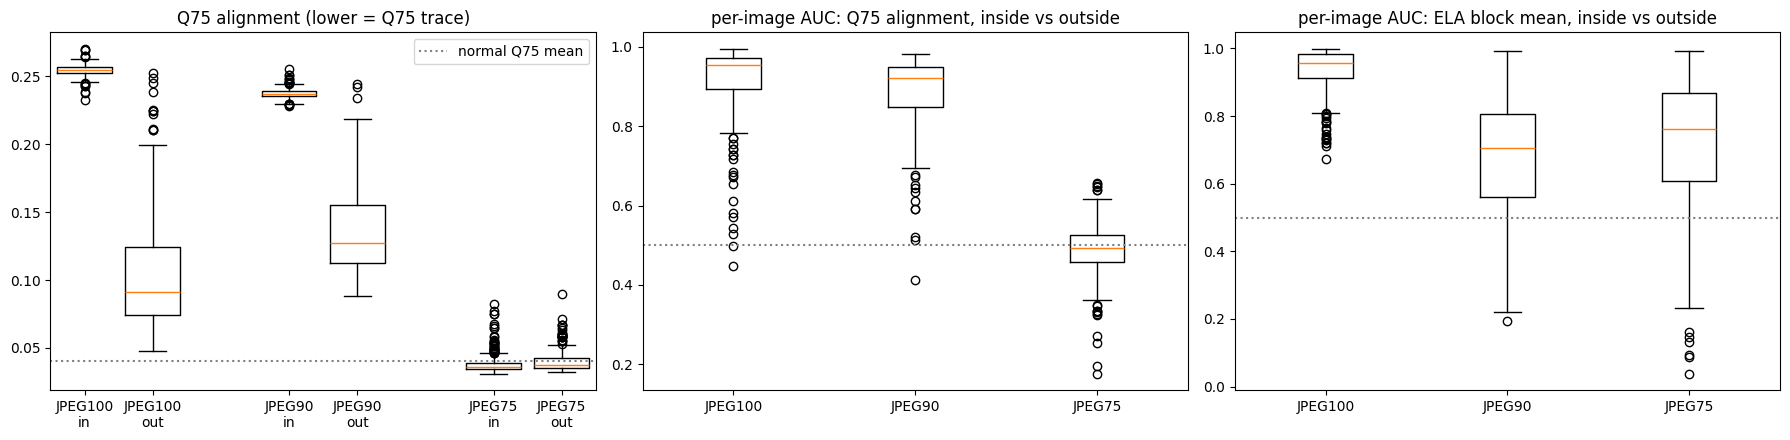

In [6]:
manipulated = autosplice_rows[autosplice_rows.kind == "manipulated"]
normal = autosplice_rows[autosplice_rows.kind == "normal"]
summary = manipulated.groupby("variant", sort=False).agg(
    images=("image", "size"), q75_inside=("q75_inside", "mean"), q75_outside=("q75_outside", "mean"),
    q75_auc=("q75_auc", "mean"),
    q90_inside=("q90_inside", "mean"), q90_outside=("q90_outside", "mean"),
    ela_inside=("ela_inside", "mean"), ela_outside=("ela_outside", "mean"), ela_auc=("ela_auc", "mean"),
    bai=("bai", "mean"))
summary["outside_lower_share"] = manipulated.assign(lower=manipulated.q75_outside < manipulated.q75_inside).groupby("variant", sort=False).lower.mean()
reference = pd.DataFrame([dict(variant="normal original (Q75)", images=len(normal), q75_outside=normal.q75_alignment_all.mean(),
                               q90_outside=normal.q90_alignment_all.mean(), ela_outside=normal.ela_all.mean(), bai=normal.bai.mean())]).set_index("variant")
print("조작 이미지: 마스크 안·밖 평균(이미지별 평균의 평균). AUC는 이미지별 값의 평균, NaN 제외")
print("outside_lower_share: 마스크 밖 Q75 정렬도가 안보다 낮은(Q75 흔적이 더 강한) 이미지 비율")
with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 200):
    display(pd.concat([summary, reference]))
    display(manipulated.groupby("variant", sort=False)[["q75_auc", "ela_auc"]].describe().T)

figure, axes = plt.subplots(1, 3, figsize=(18, 4.5))
variants = list(manipulated.variant.unique())
positions = np.arange(len(variants))
for offset, (column, label) in enumerate([("q75_inside", "inside"), ("q75_outside", "outside")]):
    data = [manipulated[manipulated.variant == v][column].dropna() for v in variants]
    axes[0].boxplot(data, positions=positions * 3 + offset, widths=0.8)
axes[0].set_xticks(np.concatenate([positions * 3, positions * 3 + 1]),
                   [f"{v}\nin" for v in variants] + [f"{v}\nout" for v in variants])
axes[0].axhline(normal.q75_alignment_all.mean(), color="gray", linestyle=":", label="normal Q75 mean")
axes[0].set_title("Q75 alignment (lower = Q75 trace)")
axes[0].legend()
axes[1].boxplot([manipulated[manipulated.variant == v].q75_auc.dropna() for v in variants])
axes[1].set_xticks(positions + 1, variants)
axes[1].axhline(0.5, color="gray", linestyle=":")
axes[1].set_title("per-image AUC: Q75 alignment, inside vs outside")
axes[2].boxplot([manipulated[manipulated.variant == v].ela_auc.dropna() for v in variants])
axes[2].set_xticks(positions + 1, variants)
axes[2].axhline(0.5, color="gray", linestyle=":")
axes[2].set_title("per-image AUC: ELA block mean, inside vs outside")
plt.tight_layout()
plt.show()

## 5. CocoGlide: JPEG 격자 흔적과 기준선

CocoGlide PNG 원본(정상·조작)의 BAI를 AutoSplice 정상 원본(Q75)과 비교하고, 정렬도가 Q75 표에 맞는지(크기 조정 없이 Q75 JPEG를 PNG로 바꾼 경우에만 낮게 나옴)도 기록함. ELA 안·밖 평균은 U-Net 입력과 같은 JPEG100 4:4:4 변환본에서 잼. 전부 조작 예측 기준선 F1도 계산함.

CocoGlide 1024장 측정 10s
bai_png·q75_alignment_png: CocoGlide는 PNG 원본, AutoSplice는 JPEG 파일에서 측정


,images,bai_png,q75_alignment_png,ela_all,ela_inside,ela_outside,mask_ratio,all_ones_f1
kind,,,,,,,,
manipulated,512,0.9955,0.2555,46.6922,47.8256,48.1012,0.2522,0.3546
normal,512,1.0031,0.2556,49.7072,NaN,NaN,NaN,NaN
AutoSplice normal (Q75 JPEG),228,1.2247,0.0401,11.2841,NaN,NaN,NaN,NaN
AutoSplice manipulated JPEG100,335,1.1107,0.1882,18.9547,NaN,NaN,0.4140,0.5404


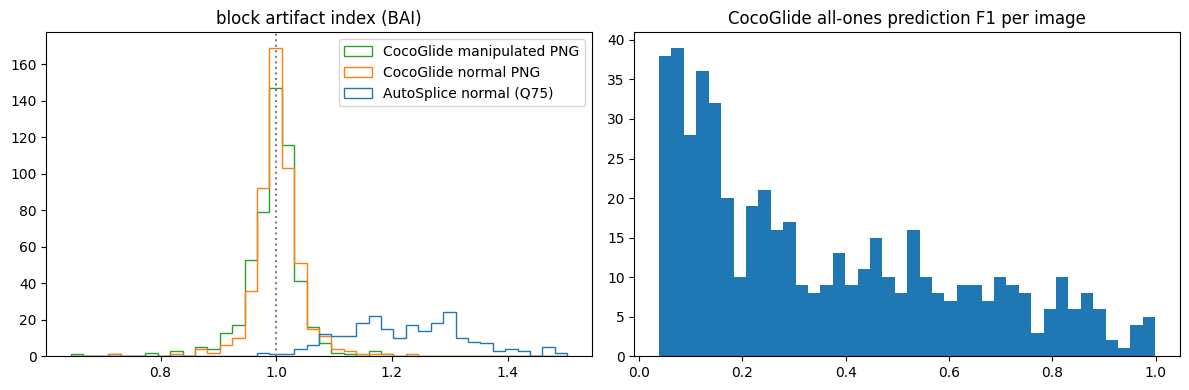

In [7]:
rows = []
start = time.perf_counter()
for record in cocoglide:
    y = luma(record["image_path"])
    rgb = load_rgb(record["jpeg_path"])
    ela_map = ela_of(rgb).astype(np.float64).mean(axis=2)
    row = dict(kind=record["kind"], image=Path(record["image_path"]).name, height=y.shape[0], width=y.shape[1],
               bai_png=bai(y), q75_alignment_png=np.nanmean(alignment_map(y, tables[75])), ela_all=ela_map.mean())
    if record["kind"] == "manipulated":
        mask = load_binary_mask(record["mask_path"], foreground_value=config["mask_foreground"])
        inside = mask > 0
        row.update(mask_ratio=inside.mean(), ela_inside=ela_map[inside].mean() if inside.any() else np.nan,
                   ela_outside=ela_map[~inside].mean() if (~inside).any() else np.nan,
                   all_ones_f1=pixel_f1(int(inside.sum()), int((~inside).sum()), 0))
    rows.append(row)
cocoglide_rows = pd.DataFrame(rows)
cocoglide_rows.to_csv(run_root / "cocoglide_rows.csv", index=False)
print(f"CocoGlide {len(cocoglide_rows)}장 측정 {time.perf_counter() - start:.0f}s")

coco_summary = cocoglide_rows.groupby("kind").agg(images=("image", "size"), bai_png=("bai_png", "mean"),
                                                  q75_alignment_png=("q75_alignment_png", "mean"), ela_all=("ela_all", "mean"),
                                                  ela_inside=("ela_inside", "mean"), ela_outside=("ela_outside", "mean"),
                                                  mask_ratio=("mask_ratio", "mean"), all_ones_f1=("all_ones_f1", "mean"))
autosplice_reference = pd.DataFrame([
    dict(kind="AutoSplice normal (Q75 JPEG)", images=len(normal), bai_png=normal.bai.mean(),
         q75_alignment_png=normal.q75_alignment_all.mean(), ela_all=normal.ela_all.mean()),
    dict(kind="AutoSplice manipulated JPEG100", images=len(manipulated[manipulated.variant == "JPEG100"]),
         bai_png=manipulated[manipulated.variant == "JPEG100"].bai.mean(),
         q75_alignment_png=manipulated[manipulated.variant == "JPEG100"].q75_alignment_all.mean(),
         ela_all=manipulated[manipulated.variant == "JPEG100"].ela_all.mean(),
         mask_ratio=manipulated[manipulated.variant == "JPEG100"].mask_ratio.mean(),
         all_ones_f1=manipulated[manipulated.variant == "JPEG100"].all_ones_f1.mean()),
]).set_index("kind")
print("bai_png·q75_alignment_png: CocoGlide는 PNG 원본, AutoSplice는 JPEG 파일에서 측정")
with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 200):
    display(pd.concat([coco_summary, autosplice_reference]))

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist([normal.bai, cocoglide_rows[cocoglide_rows.kind == "normal"].bai_png, cocoglide_rows[cocoglide_rows.kind == "manipulated"].bai_png],
             bins=40, label=["AutoSplice normal (Q75)", "CocoGlide normal PNG", "CocoGlide manipulated PNG"], histtype="step")
axes[0].axvline(1.0, color="gray", linestyle=":")
axes[0].set_title("block artifact index (BAI)")
axes[0].legend()
axes[1].hist(cocoglide_rows.all_ones_f1.dropna(), bins=40)
axes[1].set_title("CocoGlide all-ones prediction F1 per image")
plt.tight_layout()
plt.show()

## 6. 예시 그림

test에서 고정 시드로 고른 AutoSplice 조작 이미지 한 장의 Q75 정렬도 블록 지도를 JPEG 100·90·75에서 마스크와 함께 보여 줌. 어두울수록 Q75 흔적이 강한 블록임.

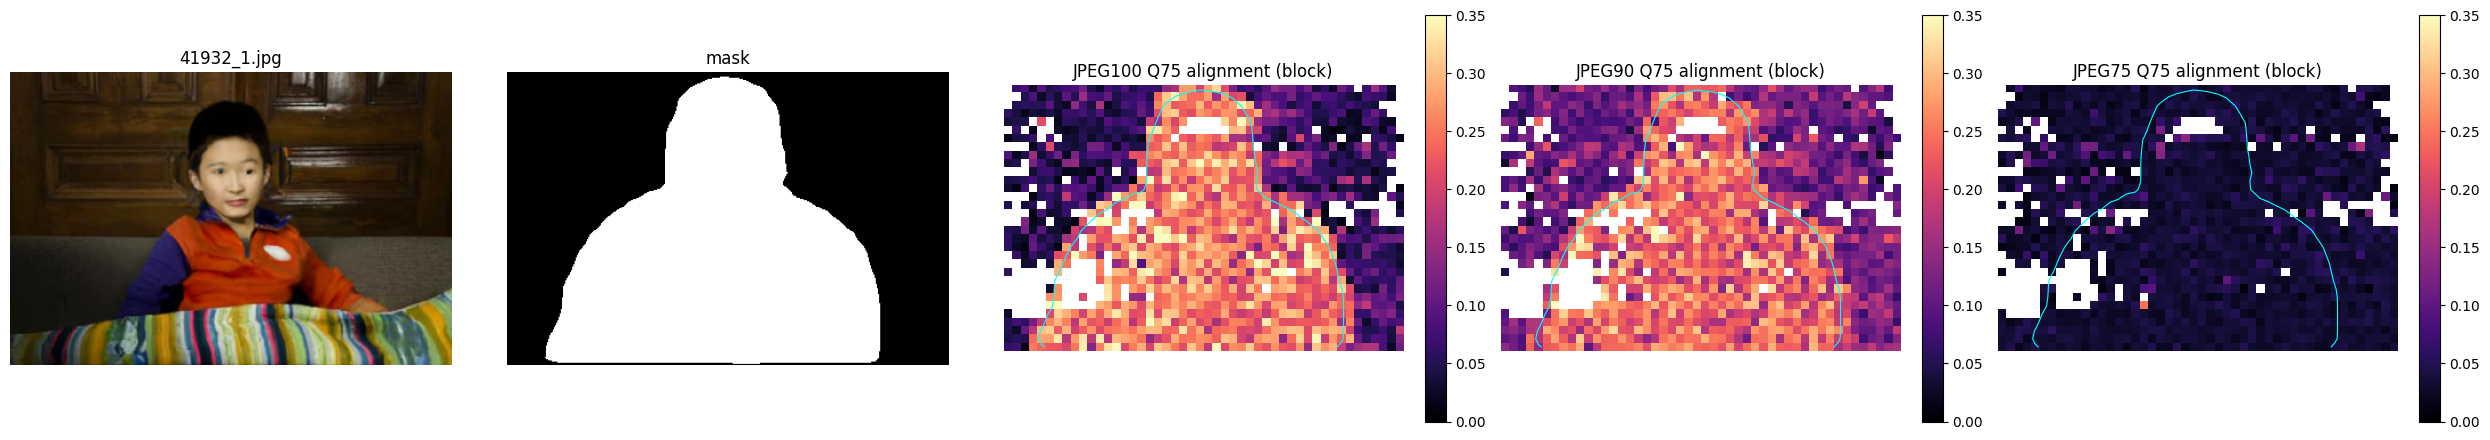

In [8]:
rng = np.random.default_rng(config["seed"])
names = sorted(r["image_path"].name for r in autosplice if r["variant"] == "JPEG100")
name = names[int(rng.integers(len(names)))]
examples = [r for r in autosplice if r["kind"] == "manipulated" and r["image_path"].name == name]
mask = load_binary_mask(examples[0]["mask_path"], foreground_value=config["mask_foreground"])
figure, axes = plt.subplots(1, 2 + len(examples), figsize=(5 * (2 + len(examples)), 4.5))
axes[0].imshow(load_rgb(examples[0]["image_path"]))
axes[0].set_title(name)
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("mask")
for axis, record in zip(axes[2:], examples):
    alignment = alignment_map(luma(record["image_path"]), tables[75])
    image = axis.imshow(alignment, cmap="magma", vmin=0, vmax=0.35)
    fraction = block_fraction(mask)
    axis.contour(fraction, levels=[0.5], colors="cyan", linewidths=0.8)
    axis.set_title(f"{record['variant']} Q75 alignment (block)")
    plt.colorbar(image, ax=axis, fraction=0.046)
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

## 7. 확인 결과와 검토 메모

아래 셀은 측정 범위를 요약함. 가설 판정과 해석은 보고서에 작성함.

사람 검토 메모(실행 후 작성):

- 3절 대조 확인(Q75 원본·Q100 재저장은 낮고, 이동·축소는 약 0.25인지):
- 4절 JPEG100에서 마스크 밖 정렬도가 안보다 낮은지, JPEG90·75에서 차이와 AUC가 줄어드는지:
- 5절 CocoGlide BAI가 1에 가까운지(격자 흔적 없음), 전부 조작 기준선과 U-Net CocoGlide F1 비교:
- 6절 예시 지도에서 Q75 흔적이 마스크 밖에만 보이는지:

In [9]:
print("측정 기록 폴더:", run_root)
print("AutoSplice test:", len(autosplice_rows), "장 / CocoGlide:", len(cocoglide_rows), "장")
for variant, group in manipulated.groupby("variant", sort=False):
    print(f"{variant}: Q75 정렬도 안 {group.q75_inside.mean():.4f} / 밖 {group.q75_outside.mean():.4f}, "
          f"Q75 AUC {group.q75_auc.mean():.4f}, ELA AUC {group.ela_auc.mean():.4f}")
print(f"CocoGlide 전부 조작 기준선 F1: {cocoglide_rows.all_ones_f1.mean():.4f}")
print("EDA 완료. 모델 선택·설정 변경에 쓰지 않음")

측정 기록 폴더: /content/drive/MyDrive/AI_Forensics_runs/kimjihwan/EXP_kimjihwan_006_compression_trace_check
AutoSplice test: 1233 장 / CocoGlide: 1024 장
JPEG100: Q75 정렬도 안 0.2545 / 밖 0.1046, Q75 AUC 0.9197, ELA AUC 0.9367
JPEG90: Q75 정렬도 안 0.2373 / 밖 0.1366, Q75 AUC 0.8861, ELA AUC 0.6817
JPEG75: Q75 정렬도 안 0.0386 / 밖 0.0401, Q75 AUC 0.4886, ELA AUC 0.7226
CocoGlide 전부 조작 기준선 F1: 0.3546
EDA 완료. 모델 선택·설정 변경에 쓰지 않음


## 8. 추가 분석: 마스크 밖 픽셀이 원본과 같은가

CocoGlide가 마스크 안만 생성한 **부분 편집**인지, 이미지 전체가 생성 모델을 거친 **재생성**인지 확인함. 같은 장면의 정상본과 조작본의 픽셀 차이를 마스크 안·밖에서 비교함. 비교용으로 AutoSplice test의 Q75 정상 원본과 JPEG100 조작본도 같은 방식으로 측정함(마스크 밖은 Q100 재저장 정도의 작은 차이만 있어야 함).

- 픽셀 차이: RGB 0~255에서 세 채널 절댓값 차이의 평균
- 밖 8 초과 비율: 마스크 밖 픽셀 중 차이가 8을 넘는 비율
- 마스크 경계에서 8픽셀 이내는 경계 번짐을 피하려고 밖에서 제외함(밖 = 마스크를 8픽셀 팽창한 영역의 바깥)
- 크기가 다른 쌍은 계산하지 않고 개수만 기록함

크기가 달라 제외한 쌍: {'CocoGlide': 0, 'AutoSplice JPEG100': 0}


,pairs,diff_inside,diff_outside,diff_outside_median,diff_outside_max,outside_over8
dataset,,,,,,
AutoSplice JPEG100,335,66.2821,0.3981,0.2764,5.3487,0.0015
CocoGlide,512,52.0054,0.2650,0.2410,1.0000,0.0000


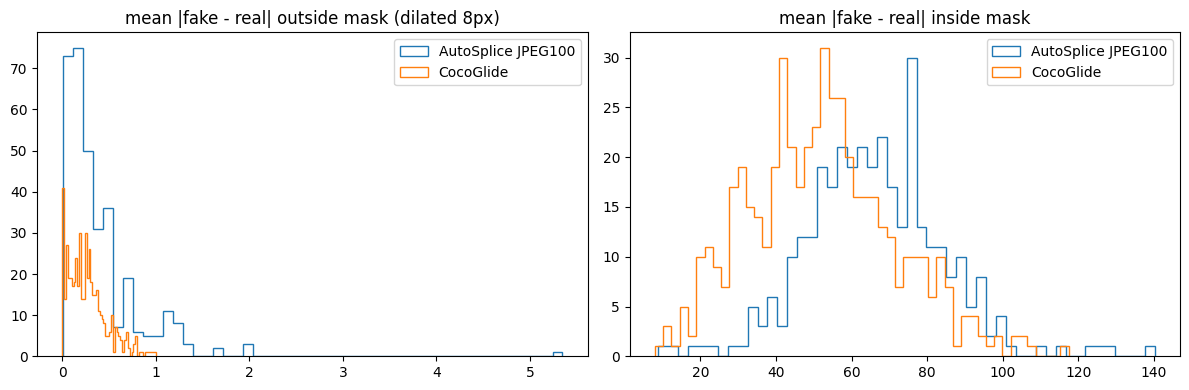

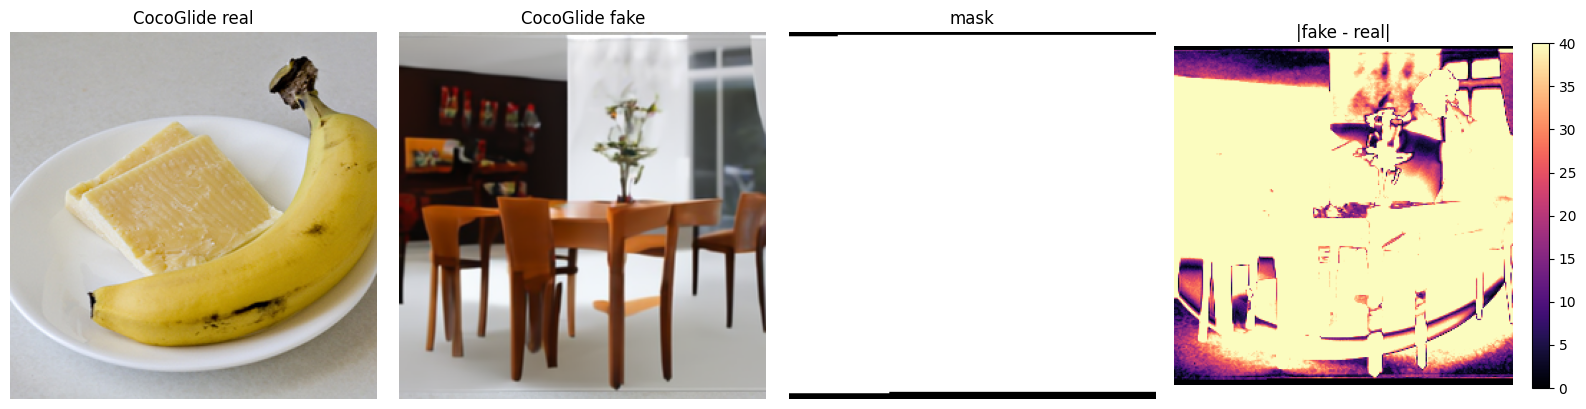

In [5]:
from scipy.ndimage import binary_dilation


def pair_difference(fake_path, real_path, mask_path):
    fake, real = load_rgb(fake_path), load_rgb(real_path)
    mask = load_binary_mask(mask_path, foreground_value=config["mask_foreground"]) > 0
    if fake.shape != real.shape or fake.shape[:2] != mask.shape:
        return None
    difference = np.abs(fake.astype(np.int16) - real.astype(np.int16)).mean(axis=2)
    outside = ~binary_dilation(mask, iterations=8)
    return dict(diff_inside=float(difference[mask].mean()) if mask.any() else np.nan,
                diff_outside=float(difference[outside].mean()) if outside.any() else np.nan,
                outside_over8=float((difference[outside] > 8).mean()) if outside.any() else np.nan,
                outside_share=float(outside.mean()))


pair_rows, size_mismatch = [], {"CocoGlide": 0, "AutoSplice JPEG100": 0}
for record in cocoglide:
    if record["kind"] != "manipulated":
        continue
    result = pair_difference(record["image_path"], record["real_path"], record["mask_path"])
    if result is None:
        size_mismatch["CocoGlide"] += 1
        continue
    pair_rows.append(dict(dataset="CocoGlide", image=Path(record["image_path"]).name, **result))
for record in autosplice:
    if record["kind"] != "manipulated" or record["variant"] != "JPEG100":
        continue
    result = pair_difference(record["image_path"], record["real_path"], record["mask_path"])
    if result is None:
        size_mismatch["AutoSplice JPEG100"] += 1
        continue
    pair_rows.append(dict(dataset="AutoSplice JPEG100", image=Path(record["image_path"]).name, **result))
pair_frame = pd.DataFrame(pair_rows)
pair_frame.to_csv(run_root / "pair_difference_rows.csv", index=False)
print("크기가 달라 제외한 쌍:", size_mismatch)
with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 200):
    display(pair_frame.groupby("dataset").agg(pairs=("image", "size"), diff_inside=("diff_inside", "mean"),
                                              diff_outside=("diff_outside", "mean"),
                                              diff_outside_median=("diff_outside", "median"),
                                              diff_outside_max=("diff_outside", "max"),
                                              outside_over8=("outside_over8", "mean")))

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
for dataset, group in pair_frame.groupby("dataset"):
    axes[0].hist(group.diff_outside, bins=50, histtype="step", label=dataset)
    axes[1].hist(group.diff_inside, bins=50, histtype="step", label=dataset)
axes[0].set_title("mean |fake - real| outside mask (dilated 8px)")
axes[1].set_title("mean |fake - real| inside mask")
for axis in axes:
    axis.legend()
plt.tight_layout()
plt.show()

example = next(r for r in cocoglide if r["kind"] == "manipulated")
fake, real = load_rgb(example["image_path"]), load_rgb(example["real_path"])
figure, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(real)
axes[0].set_title("CocoGlide real")
axes[1].imshow(fake)
axes[1].set_title("CocoGlide fake")
axes[2].imshow(load_binary_mask(example["mask_path"], foreground_value=config["mask_foreground"]), cmap="gray")
axes[2].set_title("mask")
if fake.shape == real.shape:
    image = axes[3].imshow(np.abs(fake.astype(np.int16) - real.astype(np.int16)).mean(axis=2), cmap="magma", vmin=0, vmax=40)
    plt.colorbar(image, ax=axes[3], fraction=0.046)
axes[3].set_title("|fake - real|")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()